# Analisis Telemetri Lintas Domain & Eksplorasi Data (EDA)
**Dataset:** `data/telemetry_dataset.csv` (4.500 sampel, 40 kolom, 8 skenario eksperimen)  
**Lingkup:** 5G O-RAN Multi-Slice (Radio gNB, Core UPF, & 3GPP NWDAF AnLF)


## Tahap 1: Pemuatan Data & Demarkasi Kolom (Data Ingestion & Demarcation)
- **Tujuan:** Memuat dataset telemetri multi-domain dan memetakan taksonomi kolom sesuai peran fungsional arsitektur sistem.
- **Target:** Dataset 4.500 sampel termuat tanpa error dan 40 kolom terkelompokkan ke dalam 5 grup taksonomi (Metadata, SLA Probe, RAN, Core UPF, dan 3GPP NWDAF).


In [5]:
# 1. Import library analisis dan konfigurasi visualisasi
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 120

DATASET_PATH = os.path.join('..', 'data', 'telemetry_dataset.csv')
if not os.path.exists(DATASET_PATH):
    DATASET_PATH = os.path.join('data', 'telemetry_dataset.csv')

df = pd.read_csv(DATASET_PATH)
print(f'Dataset berhasil dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom')


Dataset berhasil dimuat: 4,500 baris x 40 kolom


In [6]:
# 2. Pengelompokan taksonomi kolom resmi
METADATA_COLS = [
    'timestamp_utc', 'elapsed_sec', 'run_id', 'scrape_ok', 'scrape_latency_ms',
    'event_phase_id', 'event_scenario', 'event_domain', 'event_component',
    'rapp_diagnosed_bottleneck', 'rapp_confidence'
]

SLA_PROBE_COLS = [
    'e2e_slice1_tput_mbps', 'e2e_slice1_jitter_ms', 'e2e_slice1_rtt_ms', 'e2e_slice1_loss_pct',
    'e2e_slice2_rtt_ms', 'e2e_slice2_loss_pct', 'e2e_probe_freshness'
]

INFRA_RAN_COLS = [
    'ran_prb_cell1', 'ran_prb_cell2', 'ran_mcs_cell1', 'ran_mcs_cell2',
    'ran_bler_cell1', 'ran_bler_cell2', 'ran_snr_cell1', 'ran_snr_cell2'
]

INFRA_CORE_COLS = [
    'estimated_load_embb', 'estimated_load_urllc',
    'upf_backlog_bytes_embb', 'upf_backlog_bytes_urllc',
    'upf_drops_embb', 'upf_drops_urllc'
]

NWDAF_COLS = [
    'nwdaf_load_embb', 'nwdaf_load_urllc', 'nwdaf_comm_ul_bytes', 'nwdaf_comm_dl_bytes',
    'nwdaf_comm_duration_sec', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_freshness', 'nwdaf_api_status'
]

classified_total = len(METADATA_COLS) + len(SLA_PROBE_COLS) + len(INFRA_RAN_COLS) + len(INFRA_CORE_COLS) + len(NWDAF_COLS)
print(f'Total Kolom Terklasifikasi: {classified_total} / {df.shape[1]} kolom')


Total Kolom Terklasifikasi: 40 / 40 kolom


## Tahap 2: Pembersihan Data & Audit Kualitas (Data Cleansing & Quality Audit)
- **Tujuan:** Mendeteksi missing values (`NaN`), mengidentifikasi fitur bervariansi nol (konstan), dan memeriksa integritas scraping pada setiap run eksperimen.
- **Target:** Tabel audit kualitas 40 fitur dan ringkasan operasional 8 run eksperimen untuk identifikasi fitur yang tidak bervariasi.


In [7]:
# 1. Audit kelengkapan dan variansi per kolom
audit_rows = []
for col in df.columns:
    total_count = len(df[col])
    nan_count = int(df[col].isnull().sum())
    valid_count = total_count - nan_count
    pct_valid = round((valid_count / total_count) * 100.0, 1)
    
    is_numeric = pd.api.types.is_numeric_dtype(df[col])
    num_unique = df[col].nunique(dropna=True)
    is_constant = (num_unique <= 1)
    
    val_min = round(float(df[col].min()), 2) if is_numeric and valid_count > 0 else 'N/A'
    val_max = round(float(df[col].max()), 2) if is_numeric and valid_count > 0 else 'N/A'
    
    audit_rows.append({
        'Kolom': col,
        'Tipe': 'Numeric' if is_numeric else 'String',
        'Valid': valid_count,
        'NaN': nan_count,
        '% Valid': f'{pct_valid}%',
        'Unique': num_unique,
        'Status Variasi': '100% NaN' if valid_count == 0 else ('Konstan' if is_constant else 'Bervariasi'),
        'Min': str(val_min),
        'Max': str(val_max)
    })

df_audit = pd.DataFrame(audit_rows)
pd.set_option('display.max_rows', 45)
df_audit

cols_all_nan = df_audit[df_audit['Status Variasi'] == '100% NaN']['Kolom'].tolist()
cols_constant = df_audit[df_audit['Status Variasi'] == 'Konstan']['Kolom'].tolist()

print(f'Kolom 100% NaN ({len(cols_all_nan)}): {cols_all_nan}')
print(f'Kolom Konstan / Varians Nol ({len(cols_constant)}): {cols_constant}')


Kolom 100% NaN (3): ['e2e_slice1_jitter_ms', 'nwdaf_load_embb', 'nwdaf_load_urllc']
Kolom Konstan / Varians Nol (11): ['scrape_ok', 'e2e_probe_freshness', 'nwdaf_api_status', 'upf_backlog_bytes_urllc', 'upf_drops_urllc', 'ran_prb_cell2', 'ran_mcs_cell1', 'ran_bler_cell1', 'ran_bler_cell2', 'rapp_diagnosed_bottleneck', 'rapp_confidence']


In [8]:
# 2. Rincian integritas scraping dan telemetri per run eksperimen
run_summary = []
for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    dom = grp['event_domain'].iloc[0]
    n_rows = len(grp)
    scrape_ok_pct = round((grp['scrape_ok'].sum() / n_rows) * 100.0, 1)
    s1_outage_pct = round((grp['e2e_slice1_rtt_ms'].isnull().sum() / n_rows) * 100.0, 1)
    s2_rtt_mean = round(float(grp['e2e_slice2_rtt_ms'].mean()), 2)
    s2_loss_mean = round(float(grp['e2e_slice2_loss_pct'].mean()), 1)
    prb_c1_mean = round(float(grp['ran_prb_cell1'].mean()), 1)
    backlog_max = int(grp['upf_backlog_bytes_embb'].max())
    nwdaf_status = int(grp['nwdaf_api_status'].mean())
    
    run_summary.append({
        'Run ID': run_id,
        'Skenario': scen,
        'Domain': dom,
        'Sampel': n_rows,
        'Scrape OK': f'{scrape_ok_pct}%',
        'eMBB Outage': f'{s1_outage_pct}%',
        'URLLC RTT Avg (ms)': s2_rtt_mean,
        'URLLC Loss (%)': f'{s2_loss_mean}%',
        'PRB C1 Avg (%)': f'{prb_c1_mean}%',
        'Backlog Max (B)': f'{backlog_max:,}',
        'NWDAF Status': nwdaf_status
    })

df_run_summary = pd.DataFrame(run_summary)
display(df_run_summary)


,Run ID,Skenario,Domain,Sampel,Scrape OK,eMBB Outage,URLLC RTT Avg (ms),URLLC Loss (%),PRB C1 Avg (%),Backlog Max (B),NWDAF Status
0,EXP_S1_20261019_232208,S1_NORMAL_LIGHT,BASELINE,600,100.0%,0.0%,21.53,0.0%,63.0%,0,1
1,EXP_S2_20261019_234048,S2_NORMAL_HIGH,BASELINE,600,100.0%,0.0%,22.75,0.0%,74.1%,0,1
2,EXP_S3_20261019_235917,S3_RAN_OVERLOAD,RAN,600,100.0%,100.0%,29.37,5.6%,100.0%,0,1
3,EXP_S6_20261020_001105,S6_CORE_QUEUE_TBF,CORE,600,100.0%,0.0%,22.77,0.0%,74.6%,"310,234",1
4,EXP_S9_20261020_084020,S9_JOINT_OVERLOAD,JOINT,600,100.0%,100.0%,30.06,6.0%,100.0%,"310,226",1
5,EXP_S10_A_20261020_091150,S10_A_RELEASE_RAN,CORE,600,100.0%,0.0%,22.77,0.0%,72.7%,"310,218",1
6,EXP_S10_B_20261020_092453,S10_B_RELEASE_CORE,BASELINE,600,100.0%,0.0%,22.96,0.0%,74.7%,0,1
7,EXP_CLEAR_20261020_093812,CLEAR_FAULT,BASELINE,300,100.0%,0.0%,21.27,0.0%,57.8%,0,1


## Tahap 3: Pra-pemrosesan Data & Rekayasa Fitur (Data Preprocessing & Feature Engineering)
- **Tujuan:** Menghitung fitur turunan fisik, memeriksa distribusi frekuensi kelas target domain, dan menyusun daftar fitur kandidat ($X$).
- **Target:** Kolom turunan terhitung (`upf_backlog_kb`, batas grant), tabel distribusi frekuensi kelas target `event_domain`, dan daftar kandidat fitur masukan.


In [9]:
# 1. Perhitungan fitur turunan
df['upf_backlog_kb'] = df['upf_backlog_bytes_embb'] / 1024.0
df['ran_prb_pct'] = df['ran_prb_cell1'].clip(0.0, 100.0)

# 2. Distribusi frekuensi kelas target domain
target_dist = df['event_domain'].value_counts()
target_pct = df['event_domain'].value_counts(normalize=True) * 100.0
df_class_dist = pd.DataFrame({
    'Jumlah Sampel': target_dist,
    'Proporsi (%)': target_pct.round(2)
})
print('=== DISTRIBUSI KELAS TARGET (event_domain) ===')
display(df_class_dist)

# 3. Daftar fitur masukan terencana (X)
FEATURE_COLS_FINAL = [
    'ran_prb_cell1', 'ran_snr_cell1',
    'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb',
    'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_duration_sec'
]

print(f'Jumlah Fitur Masukan (X): {len(FEATURE_COLS_FINAL)} fitur')
print('Daftar Fitur X:', FEATURE_COLS_FINAL)


=== DISTRIBUSI KELAS TARGET (event_domain) ===


,Jumlah Sampel,Proporsi (%)
event_domain,,
BASELINE,2100,46.67
CORE,1200,26.67
RAN,600,13.33
JOINT,600,13.33


Jumlah Fitur Masukan (X): 8 fitur
Daftar Fitur X: ['ran_prb_cell1', 'ran_snr_cell1', 'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb', 'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes', 'nwdaf_comm_duration_sec']


## Tahap 4: Analisis Data Eksploratif (Exploratory Data Analysis / EDA)
- **Tujuan:** Menampilkan visualisasi runtun waktu lintas run, perbandingan kondisi skenario pasangan terkendali, dan matriks korelasi antar-fitur.
- **Target:** Plot runtun waktu beranotasi sekat run, boxplot pasangan terkendali (S2 vs S6 serta transisi S9 -> S10_A -> S10_B), dan heatmap korelasi Spearman.


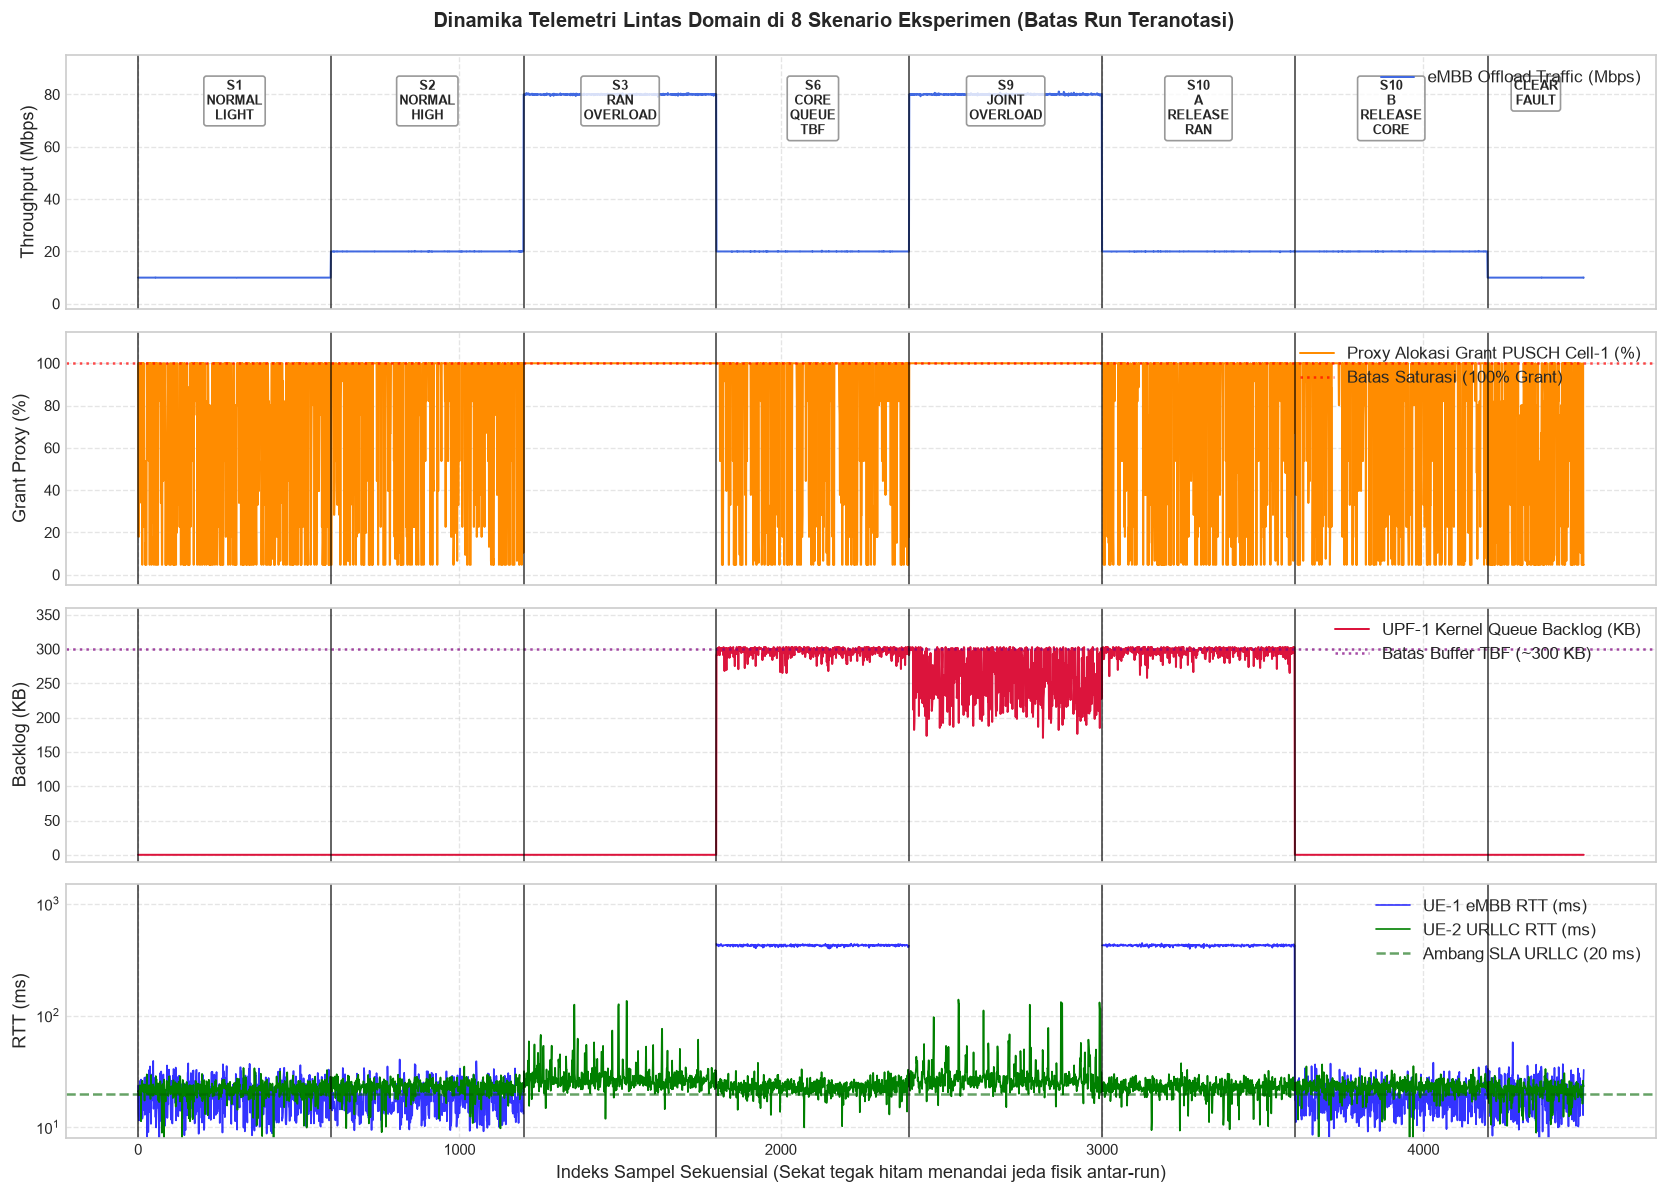

In [10]:
# 1. Dinamika runtun waktu multi-panel (Batas run nyata teranotasi)
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
x_indices = np.arange(len(df))

# Throughput eMBB
axes[0].plot(x_indices, df['e2e_slice1_tput_mbps'], color='royalblue', lw=1.2, label='eMBB Offload Traffic (Mbps)')
axes[0].set_ylabel('Throughput (Mbps)')
axes[0].set_ylim(-2, 95)
axes[0].grid(True, ls='--', alpha=0.5)
axes[0].legend(loc='upper right')

# Proxy Alokasi Grant PUSCH Cell-1
axes[1].plot(x_indices, df['ran_prb_cell1'], color='darkorange', lw=1.2, label='Proxy Alokasi Grant PUSCH Cell-1 (%)')
axes[1].axhline(100.0, color='red', ls=':', alpha=0.7, label='Batas Saturasi (100% Grant)')
axes[1].set_ylabel('Grant Proxy (%)')
axes[1].set_ylim(-5, 115)
axes[1].grid(True, ls='--', alpha=0.5)
axes[1].legend(loc='upper right')

# Kedalaman Antrean UPF (Backlog KB)
axes[2].plot(x_indices, df['upf_backlog_kb'], color='crimson', lw=1.2, label='UPF-1 Kernel Queue Backlog (KB)')
axes[2].axhline(300.0, color='purple', ls=':', alpha=0.7, label='Batas Buffer TBF (~300 KB)')
axes[2].set_ylabel('Backlog (KB)')
axes[2].set_ylim(-10, 360)
axes[2].grid(True, ls='--', alpha=0.5)
axes[2].legend(loc='upper right')

# Latensi Canary RTT UE-1 & UE-2
axes[3].plot(x_indices, df['e2e_slice1_rtt_ms'], color='blue', lw=1.0, alpha=0.8, label='UE-1 eMBB RTT (ms)')
axes[3].plot(x_indices, df['e2e_slice2_rtt_ms'], color='green', lw=1.0, label='UE-2 URLLC RTT (ms)')
axes[3].axhline(20.0, color='darkgreen', ls='--', alpha=0.6, label='Ambang SLA URLLC (20 ms)')
axes[3].set_ylabel('RTT (ms)')
axes[3].set_yscale('log')
axes[3].set_ylim(8, 1500)
axes[3].grid(True, ls='--', alpha=0.5)
axes[3].legend(loc='upper right')

# Garis sekat antar-run eksperimen
current_idx = 0
for run_id, grp in df.groupby('run_id', sort=False):
    scen = grp['event_scenario'].iloc[0]
    mid_point = current_idx + len(grp) / 2
    for ax in axes:
        ax.axvline(current_idx, color='black', ls='-', lw=1.2, alpha=0.6)
    label_clean = scen.replace('_', '\n')
    axes[0].text(mid_point, 86, label_clean, ha='center', va='top', fontsize=8, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='gray'))
    current_idx += len(grp)

axes[3].set_xlabel('Indeks Sampel Sekuensial (Sekat tegak hitam menandai jeda fisik antar-run)')
plt.suptitle('Dinamika Telemetri Lintas Domain di 8 Skenario Eksperimen (Batas Run Teranotasi)', y=0.99, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


C:\Users\idhul\AppData\Local\Temp\ipykernel_11888\767559986.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_s2_s6, x='event_scenario', y='e2e_slice1_rtt_ms', ax=axes[0], palette=['lightblue', 'salmon'])
C:\Users\idhul\AppData\Local\Temp\ipykernel_11888\767559986.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
C:\Users\idhul\AppData\Local\Temp\ipykernel_11888\767559986.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_s2_s6, x='event_scenario', y='upf_backlog_bytes_embb', ax=axes[1], pale

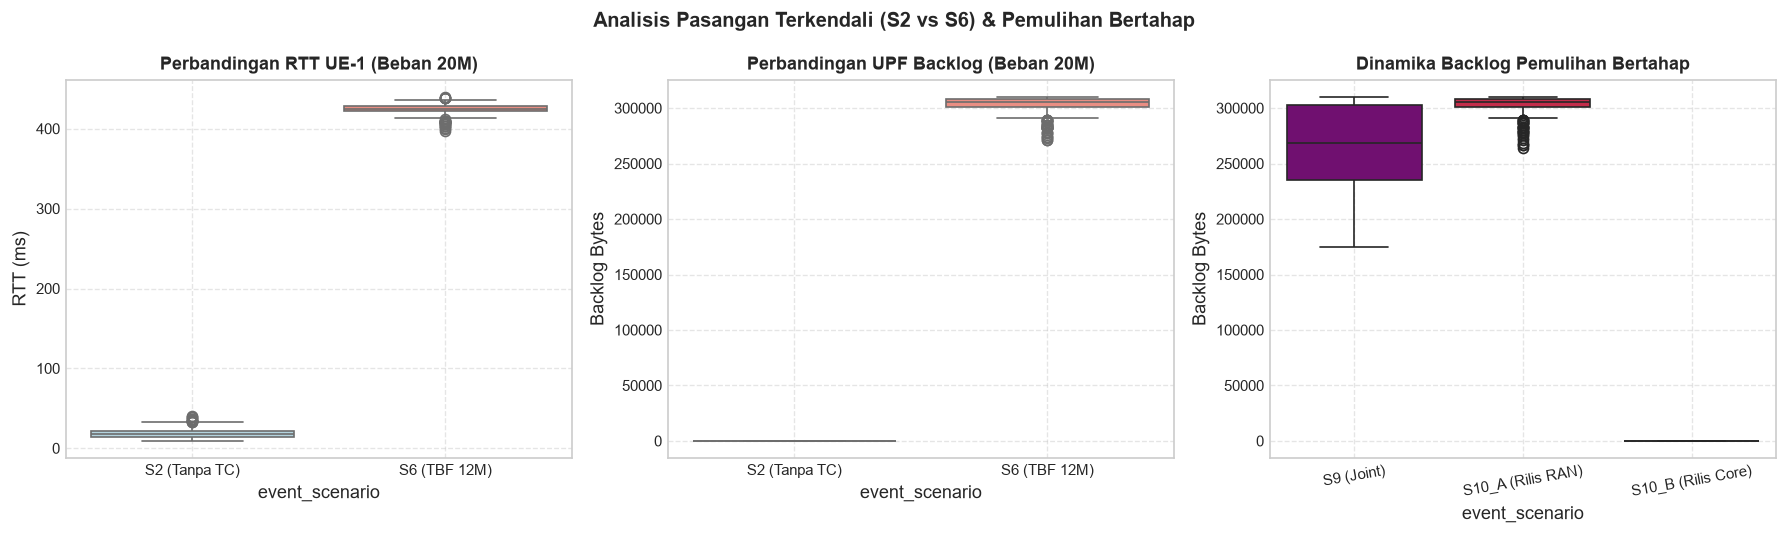

In [11]:
# 2. Evaluasi pasangan terkendali: S2 vs S6 dan Pemulihan Bertahap (Staged Recovery)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# A. Perbandingan RTT UE-1 pada S2 vs S6
df_s2_s6 = df[df['event_scenario'].isin(['S2_NORMAL_HIGH', 'S6_CORE_QUEUE_TBF'])].copy()
sns.boxplot(data=df_s2_s6, x='event_scenario', y='e2e_slice1_rtt_ms', ax=axes[0], palette=['lightblue', 'salmon'])
axes[0].set_title('Perbandingan RTT UE-1 (Beban 20M)', fontweight='bold')
axes[0].set_ylabel('RTT (ms)')
axes[0].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
axes[0].grid(True, ls='--', alpha=0.5)

# B. Perbandingan UPF Backlog pada S2 vs S6
sns.boxplot(data=df_s2_s6, x='event_scenario', y='upf_backlog_bytes_embb', ax=axes[1], palette=['lightblue', 'salmon'])
axes[1].set_title('Perbandingan UPF Backlog (Beban 20M)', fontweight='bold')
axes[1].set_ylabel('Backlog Bytes')
axes[1].set_xticklabels(['S2 (Tanpa TC)', 'S6 (TBF 12M)'])
axes[1].grid(True, ls='--', alpha=0.5)

# C. Rangkaian Pemulihan Bertahap: S9 -> S10_A -> S10_B
df_rec = df[df['event_scenario'].isin(['S9_JOINT_OVERLOAD', 'S10_A_RELEASE_RAN', 'S10_B_RELEASE_CORE'])].copy()
rec_order = ['S9_JOINT_OVERLOAD', 'S10_A_RELEASE_RAN', 'S10_B_RELEASE_CORE']
sns.boxplot(data=df_rec, x='event_scenario', y='upf_backlog_bytes_embb', order=rec_order, ax=axes[2], palette=['purple', 'crimson', 'lightgreen'])
axes[2].set_title('Dinamika Backlog Pemulihan Bertahap', fontweight='bold')
axes[2].set_ylabel('Backlog Bytes')
axes[2].set_xticklabels(['S9 (Joint)', 'S10_A (Rilis RAN)', 'S10_B (Rilis Core)'], rotation=10)
axes[2].grid(True, ls='--', alpha=0.5)

plt.suptitle('Analisis Pasangan Terkendali (S2 vs S6) & Pemulihan Bertahap', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


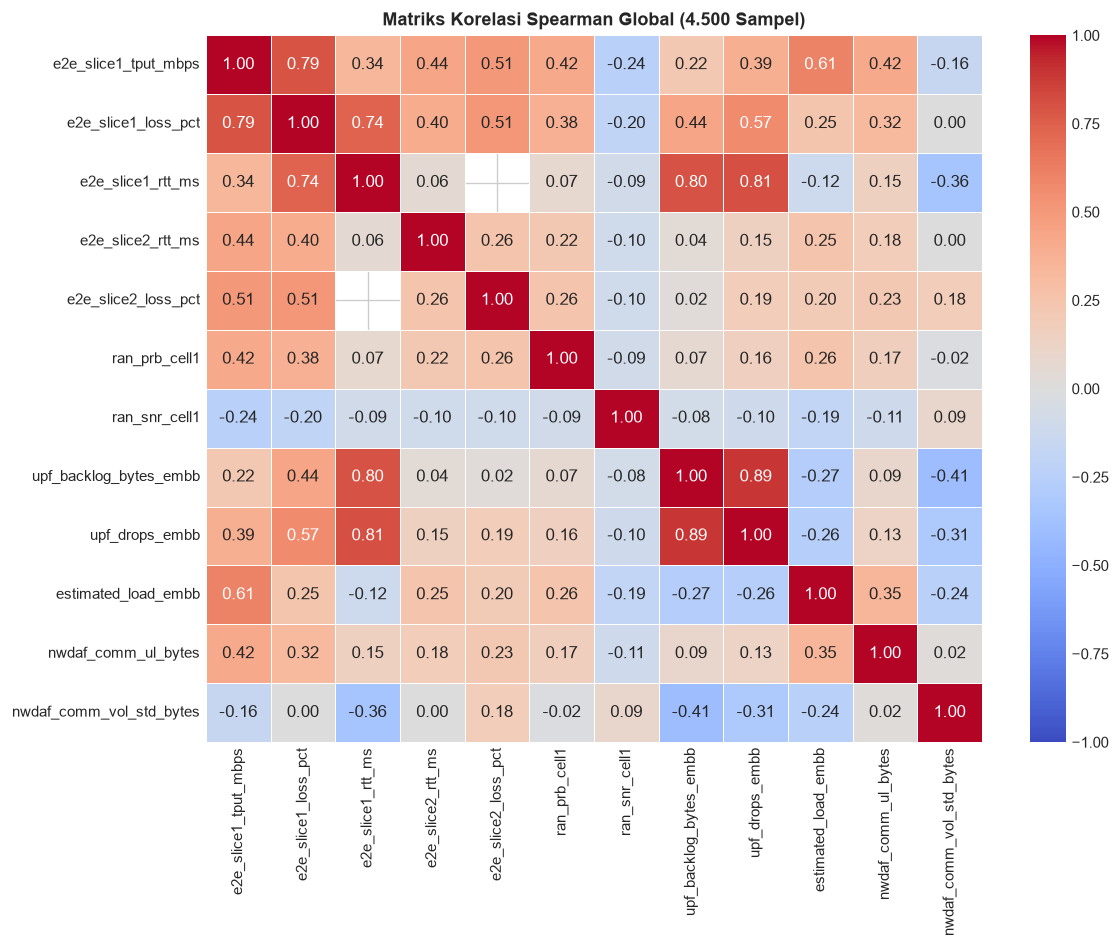

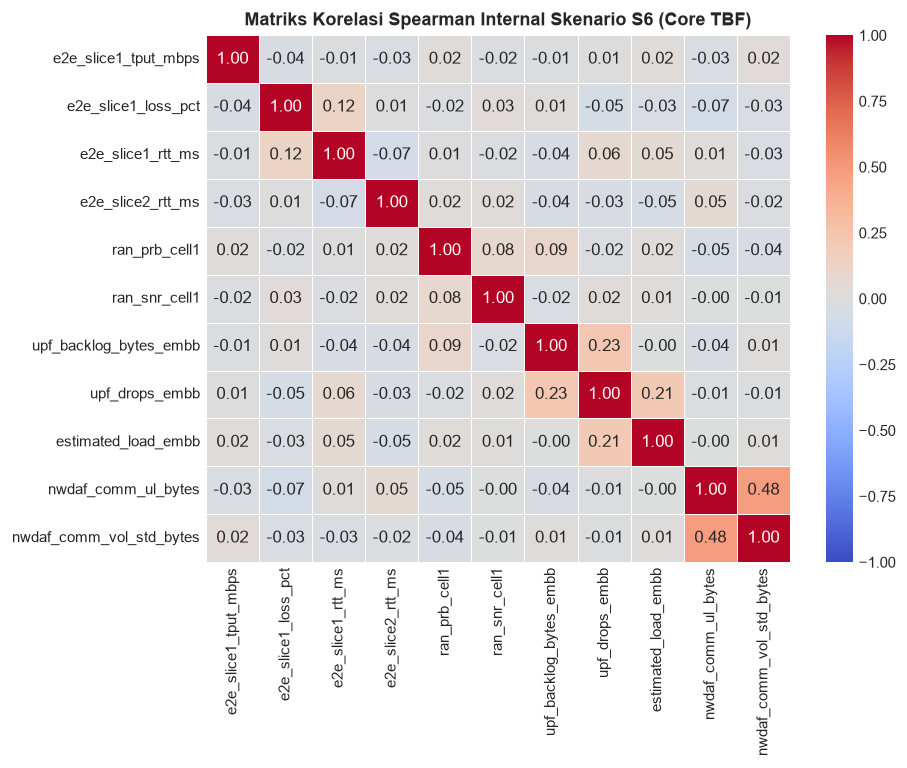

In [12]:
# 3. Matriks korelasi Spearman (Global & Internal S6)
candidate_features = [
    'e2e_slice1_tput_mbps', 'e2e_slice1_loss_pct', 'e2e_slice1_rtt_ms',
    'e2e_slice2_rtt_ms', 'e2e_slice2_loss_pct',
    'ran_prb_cell1', 'ran_snr_cell1',
    'upf_backlog_bytes_embb', 'upf_drops_embb', 'estimated_load_embb',
    'nwdaf_comm_ul_bytes', 'nwdaf_comm_vol_std_bytes'
]

# Korelasi Spearman Global
corr_global = df[candidate_features].corr(method='spearman')
plt.figure(figsize=(10, 8))
sns.heatmap(corr_global, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, linewidths=0.5)
plt.title('Matriks Korelasi Spearman Global (4.500 Sampel)', fontweight='bold')
plt.tight_layout()
plt.show()

# Korelasi Spearman Internal Skenario Core Bottleneck (S6)
df_s6 = df[df['event_scenario'] == 'S6_CORE_QUEUE_TBF'][candidate_features].dropna(axis=1, how='all')
varying_s6 = [c for c in df_s6.columns if df_s6[c].nunique() > 1]
corr_s6 = df_s6[varying_s6].corr(method='spearman')
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_s6, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, linewidths=0.5)
plt.title('Matriks Korelasi Spearman Internal Skenario S6 (Core TBF)', fontweight='bold')
plt.tight_layout()
plt.show()


## Tahap 5: Evaluasi Distribusi & Keterpisahan Data per Domain (Feature Separability Assessment)
- **Tujuan:** Menampilkan visualisasi distribusi dan matriks statistik deskriptif fitur fisik pada masing-masing label domain target.
- **Target:** Boxplot komparatif dan tabel agregasi statistik deskriptif kuantitatif (`count`, `mean`, `std`, `median`, `min`, `max`) per domain target.


C:\Users\idhul\AppData\Local\Temp\ipykernel_11888\2904806707.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='event_domain', y='ran_prb_cell1', order=domain_order, ax=axes[0], palette=palette)
C:\Users\idhul\AppData\Local\Temp\ipykernel_11888\2904806707.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='event_domain', y='upf_backlog_bytes_embb', order=domain_order, ax=axes[1], palette=palette)


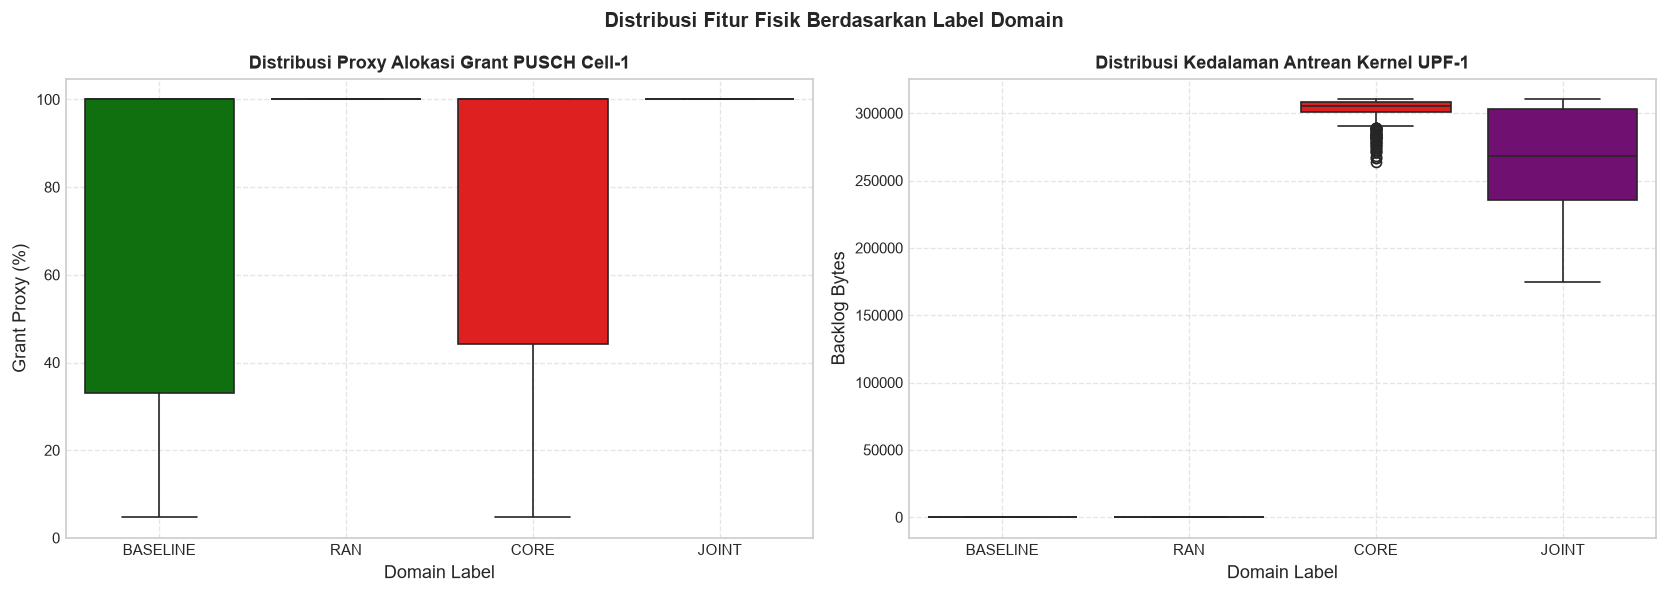

=== STATISTIK DESKRIPTIF FITUR FISIK PER DOMAIN TARGET ===


ran_prb_cell1                                       \
                     count    mean    std median     min    max   
event_domain                                                      
BASELINE              2100   68.78  38.56  100.0    4.72  100.0   
CORE                  1200   73.64  37.59  100.0    4.72  100.0   
JOINT                  600  100.00   0.00  100.0  100.00  100.0   
RAN                    600  100.00   0.00  100.0  100.00  100.0   

             upf_backlog_bytes_embb                                           \
                              count       mean       std    median       min   
event_domain                                                                   
BASELINE                       2100       0.00      0.00       0.0       0.0   
CORE                           1200  303692.67   6983.76  305690.0  264036.0   
JOINT                           600  265590.06  36113.64  268357.0  174570.0   
RAN                             600       0.00      0.00       0.0       0.0   

                       nwdaf_comm_ul_bytes                              \
                   max               count          mean           std   
event_domain                                                             
BASELINE           0.0                2095  1.670163e+09  1.259472e+09   
CORE          310234.0                1197  2.103617e+09  1.278680e+09   
JOINT         310226.0                 598  2.890415e+09  1.953256e+09   
RAN                0.0                 599  3.660936e+09  2.187210e+09   

                                               
                    median  min           max  
event_domain                                   
BASELINE      1.373935e+09  0.0  4.585925e+09  
CORE          2.064418e+09  0.0  4.592382e+09  
JOINT         3.012183e+09  0.0  6.380446e+09  
RAN           3.762535e+09  0.0  7.575908e+09

In [13]:
# 1. Visualisasi distribusi fitur fisik per label domain
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
domain_order = ['BASELINE', 'RAN', 'CORE', 'JOINT']
palette = {'BASELINE': 'green', 'RAN': 'orange', 'CORE': 'red', 'JOINT': 'purple'}

# Distribusi PRB C1 per Domain
sns.boxplot(data=df, x='event_domain', y='ran_prb_cell1', order=domain_order, ax=axes[0], palette=palette)
axes[0].set_title('Distribusi Proxy Alokasi Grant PUSCH Cell-1', fontweight='bold')
axes[0].set_xlabel('Domain Label')
axes[0].set_ylabel('Grant Proxy (%)')
axes[0].grid(True, ls='--', alpha=0.5)

# Distribusi UPF Backlog per Domain
sns.boxplot(data=df, x='event_domain', y='upf_backlog_bytes_embb', order=domain_order, ax=axes[1], palette=palette)
axes[1].set_title('Distribusi Kedalaman Antrean Kernel UPF-1', fontweight='bold')
axes[1].set_xlabel('Domain Label')
axes[1].set_ylabel('Backlog Bytes')
axes[1].grid(True, ls='--', alpha=0.5)

plt.suptitle('Distribusi Fitur Fisik Berdasarkan Label Domain', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Tabel statistik deskriptif kuantitatif per domain target
features_eval = ['ran_prb_cell1', 'upf_backlog_bytes_embb', 'nwdaf_comm_ul_bytes']
stats_per_domain = df.groupby('event_domain')[features_eval].agg(['count', 'mean', 'std', 'median', 'min', 'max']).round(2)
print('=== STATISTIK DESKRIPTIF FITUR FISIK PER DOMAIN TARGET ===')
display(stats_per_domain)
